In [28]:
# %pip install tensorflow matplotlib

In [17]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

In [ ]:
#load MINST dataset

(x_train, y_train),(x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [19]:
x_train.shape

(60000, 28, 28)

In [20]:
#Normlize the images

x_train = x_train / 255.0
x_test = x_test / 255.0

In [21]:
#Reshape the images(28x28, 1 color chanel)

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [22]:
x_train.shape

(60000, 28, 28, 1)

In [23]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPool2D(2, 2), 
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

c:\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [24]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model.fit(x_train, y_train,epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step - accuracy: 0.9495 - loss: 0.1724
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 30s 16ms/step - accuracy: 0.9826 - loss: 0.0578
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9892 - loss: 0.0385
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.9926 - loss: 0.0263
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 36s 19ms/step - accuracy: 0.9947 - loss: 0.0183


In [25]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9838 - loss: 0.0546


In [26]:
prediction = model.predict(x_test[:1])
predicted_digit = prediction.argmax()
predicted_digit

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step


np.int64(7)

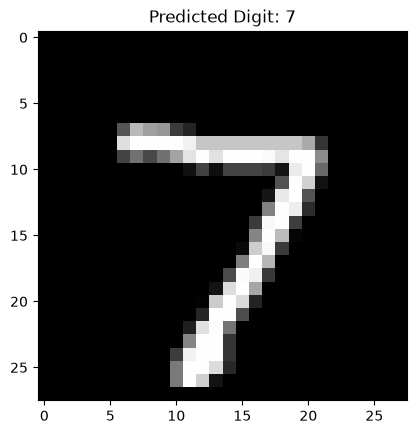

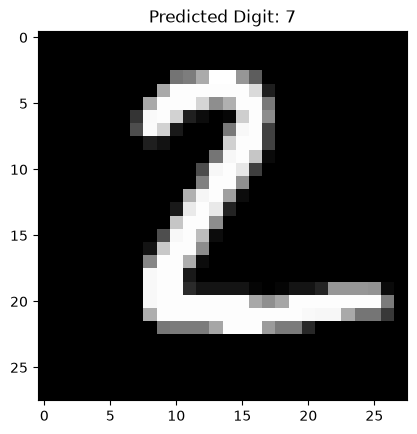

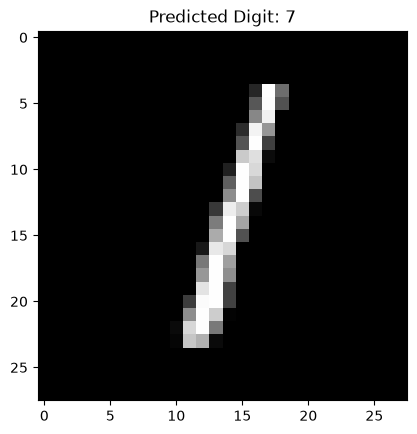

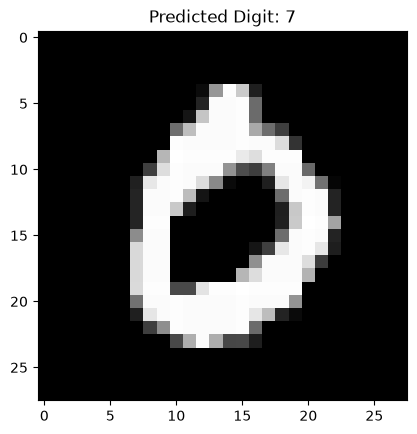

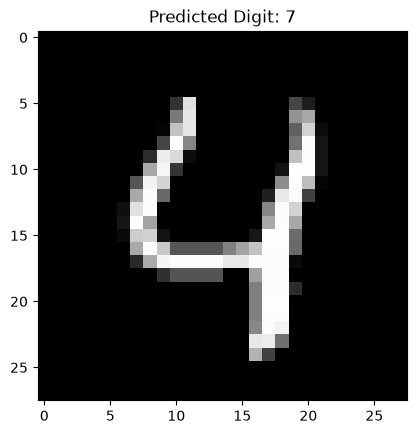

In [ ]:
for i in range(0, 5):
    # Reshape to (1, 28, 28, 1) for the model's expected batch input
    img_input = x_test[i].reshape(1, 28, 28, 1)
    prediction = model.predict(img_input)
    predicted_digit = prediction.argmax()

    plt.imshow(x_test[i].reshape(28, 28), cmap='grey')
    plt.title(f"Predicted Digit: {predicted_digit}")
    plt.show()

In [1]:
%pip install ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ---------------------------------------- 2.2/2.2 MB 10.9 MB/s  0:00:00

   ---------------------------------------- 0/3 [widgetsnbextension]
   ------------- -------------------------- 1/3 [jupyterlab_widgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3

In [30]:
import io
import numpy as np
from PIL import Image
import ipywidgets as widgets
from IPython.display import display

uploader = widgets.FileUpload(accept="image/*", multiple=False)
display(uploader)

ModuleNotFoundError: No module named 'ipywidgets'

In [ ]:
# works with both old and new ipywidgets versions
val = uploader.value
f = val[0] if isinstance(val, (tuple, list)) else list(val.values())[0]
img = Image.open(io.BytesIO(bytes(f["content"]))).convert("L").resize((28, 28))

arr = 255 - np.array(img)              # invert: MNIST = white digit on black
arr = arr.astype("float32") / 255.0
x = arr.reshape(1, 28, 28, 1)

probs = model.predict(x)[0]
pred = int(probs.argmax())
print(f"Predicted digit: {pred} ({probs[pred]:.1%} confidence)")

plt.imshow(arr, cmap="gray")
plt.title(f"Predicted: {pred}")
plt.axis("off")
plt.show()

In [ ]:
img = Image.open("my_digit.png").convert("L").resize((28, 28))